# Lire une archive pymphub depuis Python

Ce tutoriel montre comment retrouver une page, récupérer toutes ses données, savoir **sous quelle forme** elles arrivent, et continuer les calculs avec leurs incertitudes.

**À retenir tout de suite :**

- pymphub propage les incertitudes avec **[GTC](https://github.com/MSLNZ/GTC)**, et les unités avec **pint**. Il n'utilise **pas MetroloPy** pour calculer, et ne renvoie donc jamais de `uc.gummy`. Seule la *syntaxe* des unités suit celle de MetroloPy (voir la [section 9](#9.-Et-MetroloPy-?)).
- Une valeur avec incertitude est une `MesureLue` : un nombre `.valeur`, une `.unite`, et un objet GTC `.incertitude`.
- Tout ce qui est présenté ici **lit** l'archive : les pages et les données ne changent pas. Seul l'index de recherche, hors de l'historique, peut se mettre à jour.

**Lancer ce notebook**, depuis le dossier du projet :

```
uv run --with jupyterlab jupyter lab docs/tutoriel/lire_une_archive.ipynb
```

Sans rien changer, il fabrique une petite archive fictive et travaille dessus. Pour lire **votre** archive, indiquez son dossier et sa page dans la cellule suivante : les noms de grandeurs des exemples seront alors à adapter.

In [1]:
CHEMIN_ARCHIVE = None  # par exemple "D:/ArchiveStage1"
ID_PAGE = None  # par exemple "2026-11-14_activimetre-linearite_0007"

if CHEMIN_ARCHIVE is None:
    from archive_demo import creer_archive_demo

    CHEMIN_ARCHIVE, ID_PAGE = creer_archive_demo()

## 1. Ouvrir une archive et trouver une page

`Archive(chemin)` ouvre une archive, et `.page(identifiant)` relit une page : c'est la lecture « en une ligne ».

In [2]:
from pymphub import Archive

arc = Archive(CHEMIN_ARCHIVE)
arc.configuration

Configuration(version_format=1, nom='archive', site='CHU fictif', responsable='Resp.', periode_debut=datetime.date(2026, 11, 1), periode_fin=None, machines=('chu.medecine-nucleaire.activimetre.fabricant-modele.0001',))

In [3]:
arc.identifiants()  # toutes les pages, sans en relire aucune

['2026-11-14_decroissance-tc99m_0001', '2026-11-21_linearite_0002']

`chercher` filtre les pages. Tous ses critères sont facultatifs et se combinent : `tags`, `mode_tags` (`"et"` ou `"ou"`), `depuis`, `jusqua`, `gabarit`, `machine`, `statut`, `auteur`, `texte`. Le résultat va de la page la plus récente à la plus ancienne, et une page n'est relue qu'au moment où on y accède.

In [4]:
trouvees = arc.chercher(tags=["activimetre"], depuis="2026-11-01")
print(trouvees)
print(trouvees.identifiants)
print(trouvees[0])  # une page relue

print(arc.chercher(texte="Tc-99m").identifiants)  # recherche dans le texte

<2 page(s) : ['2026-11-21_linearite_0002', '2026-11-14_decroissance-tc99m_0001']>
['2026-11-21_linearite_0002', '2026-11-14_decroissance-tc99m_0001']
<Page 2026-11-21_linearite_0002 : Linéarité de l'activimètre (brouillon)>
['2026-11-14_decroissance-tc99m_0001']


In [5]:
print(arc.gabarits())  # références des gabarits
print(arc.lire_gabarit(arc.gabarits()[0]).variables[0])
print(arc.pages_illisibles())  # pages qu'il n'a pas été possible de relire

['decroissance@1']
nature='scalaire' nom='activite_ref' unite='MBq'
[]


## 2. Une page : informations, onglets et notes

In [6]:
p = arc.page(ID_PAGE)
print(p)
print("Titre       :", p.titre)
print("Date mesure :", p.date_mesure, "| type :", type(p.date_mesure).__name__)
print("Date saisie :", p.date_saisie)
print("Auteur      :", p.auteur)
print("Machine     :", p.machine)
print("Tags        :", p.tags)
print("Statut      :", p.statut)  # brouillon, validée ou corrigée
print("Gabarit     :", p.gabarit)  # None pour une page libre

<Page 2026-11-14_decroissance-tc99m_0001 : Décroissance du Tc-99m (corrigée)>
Titre       : Décroissance du Tc-99m
Date mesure : 2026-11-14 09:30:00+01:00 | type : datetime
Date saisie : 2026-11-14 09:30:00+01:00
Auteur      : G. Exemple
Machine     : chu.medecine-nucleaire.activimetre.fabricant-modele.0001
Tags        : ('activimetre', 'Tc99m')
Statut      : corrigée
Gabarit     : None


`p.onglets` décrit l'organisation de la page. Le texte d'une note garde ses tags et ses titres : `decouper_note` et `note_en_texte` donnent le texte avec les valeurs.

In [7]:
import pandas as pd

from pymphub.tags import decouper_note, note_en_texte

note = p.onglets[0]
print(note.type, "|", note.titre)
print(repr(note.texte))


def lire_tableau(nom: str) -> pd.DataFrame:
    # Utile dans toute la suite.
    return arc.lire_tableau(p.id, nom)


print(note_en_texte(decouper_note(note.texte, p.contenu, lire_tableau, k=2.0)))

notes | Notes
'# Montage\nActivité de référence : {{activite_ref}}'
# Montage
Activité de référence : 100 ± 2.1 MBq (k = 2)


`p.contenu` est la description complète de la page, telle qu'elle est écrite dans `page.json` : un modèle pydantic, avec tout ce qui n'a pas d'accès plus direct.

## 3. Que renvoie `p.mesures[nom]` ?

`p.mesures` se parcourt comme un dictionnaire. La forme renvoyée dépend de la grandeur :

| Grandeur | `p.mesures[nom]` renvoie | Valeurs |
|---|---|---|
| Scalaire | `MesureLue` | `.valeur` (`float`), `.unite`, `.incertitude` (GTC) |
| Résultat de calcul sur une valeur | `MesureLue` | pareil, **valeur enregistrée** |
| Indicateur | `MesureLue` | pareil, abscisse dans `p.contenu` |
| Identifiant | `Identifiant` | `.valeur` (`str`) |
| Tableau | `Tableau` : sa **description** | les données : `p.tableau(nom)` |
| Colonne calculée | `ColonneCalculee` | `.valeurs`, `.incertitudes_types` (tuples) |
| Ajustement | `Ajustement` | `.parametres`, `.covariance()` |
| Fichier | `Fichier` : sa **description** | le chemin : `p.fichiers[nom]` |

In [8]:
for nom in p.mesures:
    print(f"{nom:18} {type(p.mesures[nom]).__name__}")

activite_ref       MesureLue
activite_fin       MesureLue
T12                MesureLue
lot                Identifiant
decroissance       Tableau
comptage           Tableau
rapport            MesureLue
activite_relative  ColonneCalculee
d_activite         ColonneCalculee
P_activite         ColonneCalculee
fit                Ajustement
pic                MesureLue
releve             Fichier
dicom_CT           Fichier


## 4. Les valeurs et leurs incertitudes

Une `MesureLue` s'affiche avec son incertitude élargie à k = 2. Le k n'est jamais stocké : il se choisit à l'affichage.

In [9]:
a = p.mesures["activite_ref"]
a

<activite_ref = 100 ± 2.06204 MBq (k = 2)>

In [10]:
print("valeur       :", a.valeur, "|", type(a.valeur).__name__)
print("unité        :", a.unite, "|", type(a.unite).__name__)
print("incertitude  :", a.incertitude, "|", type(a.incertitude).__name__)
print("u (k = 1)    :", a.budget.incertitude_type)
print("U (k = 2)    :", a.elargie())
print("U (k = 3)    :", a.elargie(3))
print("U relative % :", a.elargie_relative())
print("ddl effectifs:", a.budget.ddl)
print("horodatage   :", a.horodatage)
print("commentaire  :", a.commentaire)
print("float(a)     :", float(a))

valeur       : 100.0 | float
unité        : MBq | str
incertitude  :  100.0(1.0) | UncertainReal
u (k = 1)    : 1.0310189135025605
U (k = 2)    : 2.062037827005121
U (k = 3)    : 3.0930567405076816
U relative % : 2.062037827005121
ddl effectifs: 8544.18903591656
horodatage   : None
commentaire  : Mesure de référence, répétée cinq fois
float(a)     : 100.0


**Le budget** garde chaque composante. `contribution_pourcent` est sa part dans la variance, et un `ddl` à `None` signifie des degrés de liberté infinis.

In [11]:
pd.DataFrame(a.budget.lignes)

,source,type,loi,incertitude_type,ddl,contribution_pourcent
0,répétabilité (n = 5),A,normale,0.151658,4.0,2.163688
1,certificat de la source,B,normale,1.000000,NaN,94.073377
2,afficheur,B,normale,0.200000,NaN,3.762935


**Convertir** avec `.en()` : la conversion suit l'unité et garde les corrélations. Les valeurs brutes d'une mesure répétée et les composantes telles que déclarées se lisent dans `p.contenu`.

In [12]:
print(a.en("mCi"))
print(a.en("kBq").valeur)

brute = p.contenu.grandeur("activite_ref")
print(brute.repetitions)
print(brute.composantes[1])

<activite_ref = 2.7027 ± 0.0557308 mCi (k = 2)>
100000.0
(100.2, 99.7, 100.1, 100.4, 99.6)
type='B' valeur=2.0 unite=None relative=True loi='normale' k=2.0 ddl=None source='certificat de la source' erreur_commune='CERT-114'


In [13]:
print(
    p.mesures["lot"].valeur, type(p.mesures["lot"].valeur).__name__
)  # un texte : 007 reste 007

007 str


## 5. Les tableaux

`p.tableau(nom)` renvoie un **DataFrame pandas** de nombres `float64`, sans incertitude dans les cellules numériques. Il contient, dans l'ordre :

1. les colonnes saisies : les identifiants restent du texte ;
2. les colonnes d'incertitude, y compris celles à formule comme `sqrt(N)`, recalculées à la lecture ;
3. les colonnes calculées, avec `nan` pour une ligne sans résultat.

Les unités sont dans `attrs["unites"]`.

In [14]:
t = p.tableau("decroissance")
t

,flacon,heure,activite,u_lecture,activite_relative,d_activite,P_activite
0,007,0.0,100.0,0.5,1.000,-10.9,0.00
1,007,1.0,89.1,0.5,0.891,-10.3,94.55
2,007,2.0,79.4,0.4,0.794,-8.7,178.80
3,007,4.0,63.0,0.3,0.630,-6.6,321.20
4,008,8.0,39.8,0.2,0.398,-5.8,526.80


In [15]:
print(t.dtypes)
print(t.attrs["unites"])

flacon                object
heure                float64
activite             float64
u_lecture            float64
activite_relative    float64
d_activite           float64
P_activite           float64
dtype: object
{'heure': 'h', 'activite': 'MBq', 'u_lecture': 'MBq', 'activite_relative': '1', 'd_activite': 'MBq/h', 'P_activite': 'MBq*h'}


In [16]:
p.tableau("comptage")  # u_N vient de la formule sqrt(N)

,N,u_N
0,1000.0,31.622777
1,1210.0,34.785054
2,961.0,31.000000


**La description** des colonnes, avec leurs composantes, est dans `p.mesures[nom].colonnes`.

In [17]:
for colonne in p.mesures["comptage"].colonnes:
    print(colonne.nature, colonne.nom, colonne.unite, getattr(colonne, "formule", None))

numerique N 1 None
incertitude u_N 1 sqrt(N)


### Une cellule avec son incertitude

`p.cellule(tableau, colonne, ligne)` renvoie une `MesureLue`, composantes de la colonne et de la cellule combinées.

> ⚠️ **Deux numérotations différentes.** `p.cellule` compte les lignes **à partir de 0**, comme le DataFrame. Une formule, comme `decroissance.activite[1]`, les compte **à partir de 1**, comme la grille de l'interface.

In [18]:
c = p.cellule("decroissance", "activite", 1)  # deuxième ligne
print(c)
pd.DataFrame(c.budget.lignes)[["source", "incertitude_type", "contribution_pourcent"]]

<decroissance.activite[1] = 89.1 ± 2.04341 MBq (k = 2)>


,source,incertitude_type,contribution_pourcent
0,certificat de la source,0.891,76.05091
1,"lecture, cellule par cellule",0.500,23.94909


### Toute une colonne d'incertitudes

`incertitudes_types` donne l'incertitude-type de chaque ligne en une fois : pratique pour tracer ou pour un ajustement. Elle ne garde pas les corrélations entre lignes : pour un calcul, voir la [section 8](#8.-Calculer-avec-les-incertitudes).

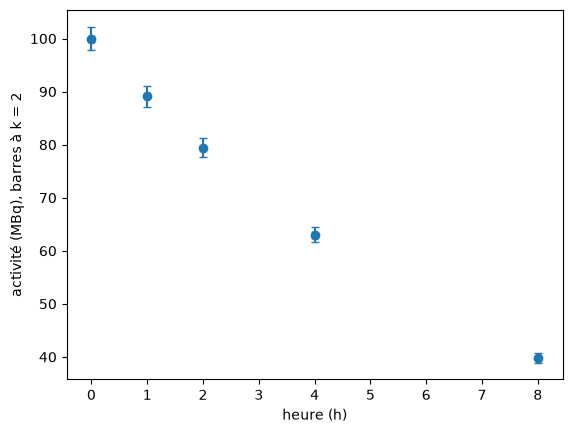

In [19]:
import matplotlib.pyplot as plt

from pymphub.graphes import incertitudes_types

u_activite = incertitudes_types(p.mesures["decroissance"], t, "activite")
u_heure = incertitudes_types(p.mesures["decroissance"], t, "heure")

plt.errorbar(
    t["heure"],
    t["activite"],
    xerr=2 * pd.Series(u_heure),
    yerr=2 * pd.Series(u_activite),
    fmt="o",
    capsize=3,
)
plt.xlabel(f"heure ({t.attrs['unites']['heure']})")
plt.ylabel(f"activité ({t.attrs['unites']['activite']}), barres à k = 2")
plt.show()

## 6. Les résultats déjà calculés dans la page

### Colonnes calculées, dont dérivées et primitives

Le DataFrame ne donne que leurs valeurs. Leurs incertitudes sont dans `p.mesures[nom]`, ligne par ligne. `budget_de_ligne` refait le budget d'une ligne, **numérotée à partir de 1**.

In [20]:
d = p.mesures["d_activite"]
print(type(d).__name__, "|", d.formule, "|", d.unite)
print("valeurs         :", d.valeurs)
print("incertitudes u  :", d.incertitudes_types)

ColonneCalculee | derivee(decroissance.activite, decroissance.heure) | MBq/h
valeurs         : (-10.900000000000006, -10.299999999999997, -8.699999999999998, -6.600000000000001, -5.800000000000001)
incertitudes u  : (0.7790564806225542, 0.3665064801609925, 0.22819898724091164, 0.10430510800318246, 0.11476497723608889)


In [21]:
from pymphub.calculs import budget_de_ligne

budget = budget_de_ligne(p.contenu, d, 2, lire_tableau)
print(budget.valeur, "±", budget.elargie(), budget.unite, "(k = 2)")
pd.DataFrame(budget.lignes)[["source", "incertitude_type", "contribution_pourcent"]]

-10.299999999999997 ± 0.733012960321985 MBq/h (k = 2)


,source,incertitude_type,contribution_pourcent
0,"decroissance.activite[1] : lecture, cellule pa...",0.250,46.528248
1,"decroissance.activite[3] : lecture, cellule pa...",0.200,29.778079
2,decroissance.heure[1] : horloge,0.103,7.897891
3,decroissance.heure[3] : horloge,0.103,7.897891
4,CERT-114,0.103,7.897891


### Grandeurs calculées : un résultat est figé

Un résultat de calcul est **enregistré tel qu'il a été calculé**. Si une valeur change ensuite, il ne se met pas à jour tout seul : `etat_derivee` le signale. Dans l'archive d'exemple, `activite_fin` a été corrigée après le calcul de `rapport`.

De plus, relu par `p.mesures`, un résultat devient une **mesure indépendante** pour GTC : ses corrélations avec les grandeurs d'origine sont perdues. Pour les garder, il faut refaire le calcul, comme en [section 8](#8.-Calculer-avec-les-incertitudes).

In [22]:
from pymphub.calculs import calculer, etat_derivee

print("Enregistré :", p.mesures["rapport"])
print(
    "État       :", etat_derivee(p.contenu, p.contenu.grandeur("rapport"), lire_tableau)
)

refait = calculer(p.contenu, p.contenu.grandeur("rapport").formule, lire_tableau)
print("Refait     :", refait.valeur, "±", refait.elargie(), "(k = 2)")

Enregistré : <rapport = 1.98807 ± 0.0186962 1 (k = 2)>
État       : Résultat à recalculer : ses grandeurs ont changé, il vaudrait 1.98413 1.
Refait     : 1.9841269841269842 ± 0.01863264887240462 (k = 2)


### Ajustements

`p.mesures[nom]` donne les coefficients et leur matrice de covariance. `evaluer_ajustement` réévalue la fonction et son incertitude, en tenant compte des covariances. Dans une formule, un coefficient s'écrit `fit.A`.

A * exp(-l * x) | méthode : Moindres carrés pondérés par l'incertitude propre de chaque point, variance effective pour x, erreurs communes propagées à part ; covariance non remise à l'échelle du χ². | chi² réduit : 0.015169085584130883
  nom     valeur  incertitude_type unite
0   A  99.962699          1.065301   MBq
1   l   0.115178          0.000880   1/h
corrélation : ((1.0, 0.2547169146558495), (0.25471691465584956, 1.0))
covariance  : ((1.1348653619353934, 0.00023889499655389102), (0.00023889499655389108, 7.75093680412822e-07))


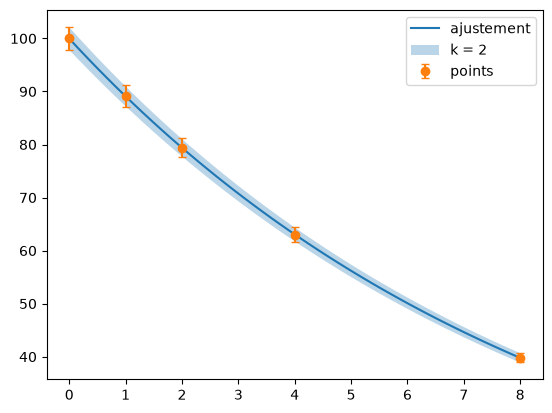

ln(2) / λ = 6.018065618883081 ± 0.09200161907043583 h (k = 2)


In [23]:
import numpy as np

from pymphub.ajustements import evaluer_ajustement

fit = p.mesures["fit"]
print(fit.formule, "| méthode :", fit.methode, "| chi² réduit :", fit.chi2_reduit)
print(pd.DataFrame([parametre.model_dump() for parametre in fit.parametres]))
print("corrélation :", fit.correlation)
print("covariance  :", fit.covariance())

x = np.linspace(fit.x_min, fit.x_max, 50)
y, u_y = evaluer_ajustement(fit, x)
plt.plot(x, y, label="ajustement")
plt.fill_between(x, y - 2 * u_y, y + 2 * u_y, alpha=0.3, label="k = 2")
plt.errorbar(
    t["heure"],
    t["activite"],
    yerr=2 * pd.Series(u_activite),
    fmt="o",
    capsize=3,
    label="points",
)
plt.legend()
plt.show()

temps_moitie = calculer(p.contenu, "ln(2) / fit.l", lire_tableau, unite="h")
print(
    "ln(2) / λ =",
    temps_moitie.valeur,
    "±",
    temps_moitie.elargie(),
    temps_moitie.unite,
    "(k = 2)",
)

### Indicateurs

Un indicateur se lit comme une mesure. Son abscisse, et les réglages utilisés, sont dans `p.contenu`.

In [24]:
pic = p.contenu.grandeur("pic")
print(p.mesures["pic"])
print(
    pic.methode,
    "| sur :",
    pic.source,
    "| abscisse :",
    pic.position,
    "±",
    pic.incertitude_position,
)

<pic = 100 ± 2.23607 MBq (k = 2)>
maximum | sur : points | abscisse : 0.0 ± 0.02


## 7. Fichiers, DICOM, pièces jointes et historique

`p.fichiers[nom]` renvoie un `pathlib.Path` **après avoir vérifié l'empreinte** du fichier : un fichier altéré ou manquant lève une erreur au lieu de donner de fausses données.

Ne modifiez pas ce fichier : c'est la donnée brute de l'archive.

In [25]:
print(list(p.fichiers))
chemin = p.fichiers["releve"]
print(type(chemin).__name__, chemin.name)
print(chemin.read_text(encoding="utf-8"))
print(p.mesures["releve"].stockage.nom_origine)  # son nom d'origine

['releve', 'dicom_CT']
PosixPath d4e0b107b9d26d0362c050a8a115e2a72ee552e10bc60896adb96513acb2f6
Relevé de l'activimètre

releve.txt


### Séries DICOM

Une série importée est un **zip** de fichiers DICOM, déjà pseudonymisés. `lire_serie` les relit un à un en objets pydicom, et `construire_volume` donne un `Volume` aux **valeurs physiques** : pente et ordonnée appliquées, ou `DoseGridScaling` pour une dose.

`volume.donnees` est un tableau numpy de forme **(t, z, y, x)**, sans incertitude.

ndarray (1, 4, 16, 16) HU CT
espacement x, y, z (mm) : (1.0, 1.0, 2.5)
voxel t=0, z=2, y=3, x=3 : 20.0 HU
position patient (mm)    : [3. 3. 5.]


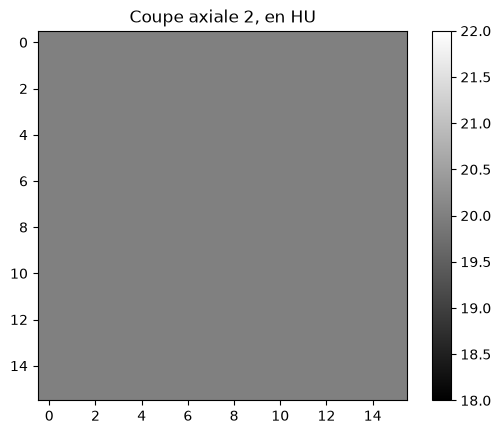

CT pseudonymise


In [26]:
from pymphub.dicom import lire_serie
from pymphub.volumes import construire_volume, coupe

volume = construire_volume(lire_serie(p.fichiers["dicom_CT"]))
print(
    type(volume.donnees).__name__, volume.donnees.shape, volume.unite, volume.modalite
)
print("espacement x, y, z (mm) :", volume.espacement)
print("voxel t=0, z=2, y=3, x=3 :", volume.valeur(0, 2, 3, 3), volume.unite)
print("position patient (mm)    :", volume.vers_patient(3, 3, 2))

plt.imshow(coupe(volume, "axial", 2), cmap="gray")
plt.title(f"Coupe axiale 2, en {volume.unite}")
plt.colorbar()
plt.show()

print(p.mesures["dicom_CT"].dicom.modalite, p.mesures["dicom_CT"].dicom.mode)

Pour une très grosse série, `volume.donnees` peut être un fichier temporaire chargé à la demande, plutôt que de la mémoire vive. Les structures d'un RTSTRUCT se lisent avec `pymphub.volumes.lire_structures(jeu)`.

### Pièces jointes

In [27]:
for piece in p.contenu.pieces_jointes:
    print(piece.chemin, "|", arc.chemin_piece_jointe(p.id, piece.chemin).name)

pieces_jointes/releve.txt | releve.txt


### Historique et anciennes versions

Chaque version de la page est conservée. `p.corrections()` ne garde que les corrections motivées, et `arc.version_page` relit une ancienne version.

In [28]:
for entree in p.historique():
    print(
        entree.date.date(),
        entree.nature,
        "|",
        entree.motif,
        "|",
        len(entree.modifications),
        "champ(s)",
    )

correction = p.corrections()[0]
print(correction.motif)
for modification in correction.modifications:
    print(" ", modification.champ, ":", modification.ancien, "→", modification.nouveau)

ancienne = arc.version_page(p.id, p.historique()[1].commit)
print("Avant correction :", ancienne.grandeur("activite_fin").valeur)

2026-11-03 création | None | 0 champ(s)
2026-11-03 enregistrement | None | 4 champ(s)
2026-11-03 enregistrement | None | 5 champ(s)
2026-11-03 validation | None | 1 champ(s)
2026-11-03 correction | Erreur de recopie sur l'activité finale | 2 champ(s)
Erreur de recopie sur l'activité finale
  statut : validée → corrigée
  mesures.activite_fin.valeur : 50.3 → 50.4


Avant correction : 50.3


## 8. Calculer avec les incertitudes

Il y a deux façons de faire, à ne pas mélanger :

| | `calculer` de pymphub | GTC à la main |
|---|---|---|
| Écriture | Une formule en texte, comme dans l'onglet Calculs | Du Python sur des objets GTC |
| Unités | **Vérifiées et converties** | **Aucune** : à gérer soi-même |
| Corrélations | Automatiques | Si l'on réutilise les mêmes objets |
| Liberté | Fonctions autorisées seulement | Tout le Python |

### 8.1 Avec `calculer` : le plus sûr

Fonctions permises : `exp ln log10 sqrt sin cos tan`, la constante `pi`, et `derivee(y, x)` et `primitive(y, x)` pour une colonne. La formule n'est jamais exécutée comme du Python.

In [29]:
from pymphub.calculs import ErreurCalcul

try:
    calculer(p.contenu, "activite_ref * exp(-ln(2) * 3 / T12)", lire_tableau)
except ErreurCalcul as erreur:
    print("Refusé :", erreur)

Refusé : La fonction exp attend une grandeur sans dimension, pas des 1/h.


Les unités sont vérifiées : la formule ci-dessus est refusée, car `3` n'a pas d'unité alors que `T12` est en heures, et un exposant doit être sans dimension. Une formule ne peut pas écrire `3 h` : pour indiquer un temps, utilisez une grandeur ou une cellule de la page.

In [30]:
budget = calculer(
    p.contenu, "activite_ref * exp(-ln(2) * decroissance.heure[3] / T12)", lire_tableau
)
print(f"A(t) = {budget.valeur:.3f} ± {budget.elargie():.3f} {budget.unite} (k = 2)")
print("ddl effectifs :", budget.ddl)
print("Objet GTC     :", budget.gtc)
pd.DataFrame(budget.lignes)[
    ["source", "type", "incertitude_type", "contribution_pourcent"]
]

A(t) = 79.401 ± 1.679 MBq (k = 2)
ddl effectifs : 9445.798088653548
Objet GTC     :  79.40(84)


,source,type,incertitude_type,contribution_pourcent
0,CERT-114,B,0.794006,89.471111
1,decroissance.heure[3] : horloge,B,0.183149,4.760415
2,activite_ref : afficheur,B,0.158801,3.578844
3,activite_ref : répétabilité (n = 5),A,0.120417,2.057836
4,T12 : ICRP,B,0.030474,0.131794


Le résultat est un `Budget`, avec `.valeur`, `.unite`, `.incertitude_type`, `.elargie(k)`, `.ddl`, `.lignes`, `.gtc` et `.en(unite)`.

**Une erreur commune se compense là où elle doit.** `activite_ref` et `activite_fin` partagent le certificat `CERT-114` : dans leur rapport, il ne compte plus. Sans cette information, on surestimerait fortement l'incertitude.

In [31]:
rapport = calculer(p.contenu, "activite_ref / activite_fin", lire_tableau)
print(f"rapport = {rapport.valeur:.4f}, u = {rapport.incertitude_type:.4f}")
pd.DataFrame(rapport.lignes)[["source", "incertitude_type", "contribution_pourcent"]]

rapport = 1.9841, u = 0.0093


,source,incertitude_type,contribution_pourcent
0,activite_fin : afficheur,0.007874,71.424735
1,activite_ref : afficheur,0.003968,18.143025
2,activite_ref : répétabilité (n = 5),0.003009,10.432240
3,CERT-114,0.000000,0.000000


Une formule avec une colonne entière, comme `decroissance.activite`, donne une colonne : c'est `creer_resultat` qui la calcule, sans rien enregistrer tant qu'on ne l'écrit pas dans l'archive. Il choisit seul entre une valeur et une colonne.

In [32]:
from pymphub.calculs import creer_resultat

ecart = creer_resultat(
    p.contenu, "ecart", "decroissance.activite - activite_ref", lire_tableau
)
print(type(ecart).__name__, ecart.unite)
print(ecart.valeurs)
print(ecart.incertitudes_types)

ColonneCalculee MBq
(0.0, -10.900000000000006, -20.599999999999994, -37.0, -60.2)
(0.5594640292279749, 0.5699833330896619, 0.5152048136421091, 0.5384236250388725, 0.6822052477077558)


### 8.2 La dérivée et la primitive d'une colonne

- **Dérivée** : différence centrée `(y[i+1] − y[i−1]) / (x[i+1] − x[i−1])`, décentrée aux deux bouts.
- **Primitive** : trapèzes cumulés, avec 0 à la première ligne.
- **x** doit croître ou décroître strictement.

L'incertitude n'a pas de formule à part : chaque valeur est un objet GTC, et GTC propage au premier ordre dans ces opérations, en tenant compte des erreurs partagées. **L'erreur de méthode, due au pas de la discrétisation, n'y est pas comptée.**

In [33]:
derivee = creer_resultat(
    p.contenu, "d", "derivee(decroissance.activite, decroissance.heure)", lire_tableau
)
primitive = creer_resultat(
    p.contenu, "P", "primitive(decroissance.activite, decroissance.heure)", lire_tableau
)

print(derivee.unite, primitive.unite)
pd.DataFrame(
    {
        "heure": t["heure"],
        "dA/dt": derivee.valeurs,
        "u(dA/dt)": derivee.incertitudes_types,
        "primitive": primitive.valeurs,
        "u(primitive)": primitive.incertitudes_types,
    }
)

MBq/h MBq*h


,heure,dA/dt,u(dA/dt),primitive,u(primitive)
0,0.0,-10.9,0.779056,0.00,0.000000
1,1.0,-10.3,0.366506,94.55,2.858449
2,2.0,-8.7,0.228199,178.80,3.163382
3,4.0,-6.6,0.104305,321.20,4.098007
4,8.0,-5.8,0.114765,526.80,5.856139


### 8.3 Le même calcul avec GTC à la main

Voici ce qui se passe à l'intérieur. Un objet GTC, un `UncertainReal`, retient de quelles erreurs il dépend ; les opérations habituelles le propagent, et `GTC.exp`, `GTC.log`, `GTC.sqrt`… remplacent celles de `math` ou de numpy.

> ⚠️ **Gardez les mêmes objets.** Chaque appel à `p.cellule` crée une nouvelle mesure, indépendante de la précédente, sauf pour ses erreurs communes : deux lectures de la même cellule ne sont donc pas « la même mesure » pour GTC. Relisez chaque cellule **une seule fois**, puis réutilisez l'objet.

In [34]:
import GTC

deux_fois = (
    p.cellule("decroissance", "activite", 1).incertitude
    - p.cellule("decroissance", "activite", 1).incertitude
)
print(
    "Deux lectures :", GTC.uncertainty(deux_fois), " ← devrait être 0 : c'est le piège"
)

une_fois = p.cellule("decroissance", "activite", 1).incertitude
print("Même objet    :", GTC.uncertainty(une_fois - une_fois))

Deux lectures : 0.7071067811865476  ← devrait être 0 : c'est le piège
Même objet    : 0.0


In [35]:
n = len(t)
y = [p.cellule("decroissance", "activite", i).incertitude for i in range(n)]
x = [p.cellule("decroissance", "heure", i).incertitude for i in range(n)]

# La dérivée, ligne par ligne.
derivee_gtc = []
for i in range(n):
    avant, apres = max(i - 1, 0), min(i + 1, n - 1)
    derivee_gtc.append((y[apres] - y[avant]) / (x[apres] - x[avant]))

# La primitive : on ajoute un trapèze à chaque ligne.
primitive_gtc = [GTC.ureal(0.0, 0.0)]
for i in range(1, n):
    primitive_gtc.append(primitive_gtc[-1] + (y[i - 1] + y[i]) / 2 * (x[i] - x[i - 1]))

comparaison = pd.DataFrame(
    {
        "dérivée GTC": [GTC.value(v) for v in derivee_gtc],
        "dérivée pymphub": derivee.valeurs,
        "u GTC": [GTC.uncertainty(v) for v in derivee_gtc],
        "u pymphub": derivee.incertitudes_types,
    }
)
assert np.allclose(comparaison["u GTC"], comparaison["u pymphub"])
assert np.allclose(
    [GTC.uncertainty(v) for v in primitive_gtc], primitive.incertitudes_types
)
comparaison

,dérivée GTC,dérivée pymphub,u GTC,u pymphub
0,-10.9,-10.9,0.779056,0.779056
1,-10.3,-10.3,0.366506,0.366506
2,-8.7,-8.7,0.228199,0.228199
3,-6.6,-6.6,0.104305,0.104305
4,-5.8,-5.8,0.114765,0.114765


Les fonctions utiles de GTC, pour un objet `v` :

| Fonction | Donne |
|---|---|
| `GTC.value(v)` ou `v.x` | la valeur |
| `GTC.uncertainty(v)` ou `v.u` | l'incertitude-type |
| `GTC.dof(v)` ou `v.df` | les degrés de liberté effectifs (Welch-Satterthwaite) |
| `GTC.get_correlation(a, b)` | la corrélation entre deux résultats |
| `GTC.ureal(x, u, df=…, label=…)` | une nouvelle valeur incertaine |
| `GTC.reporting.budget(v)` | les composantes de `v` |

Deux lignes d'une dérivée qui utilisent un même point sont corrélées, et le certificat commun relie aussi les autres. Ne les traitez donc pas comme des valeurs indépendantes.

In [36]:
import GTC.reporting

v = derivee_gtc[1]
print("valeur, u, ddl :", v.x, v.u, v.df)
print(
    "Lignes 2 et 4, qui partagent un point :",
    GTC.get_correlation(derivee_gtc[1], derivee_gtc[3]),
)
print(
    "Lignes 1 et 5, reliées par le certificat :",
    GTC.get_correlation(derivee_gtc[0], derivee_gtc[4]),
)

for influence in GTC.reporting.budget(derivee_gtc[1]):
    print(f"  {influence.label:30} {influence.u:.4f}")

valeur, u, ddl : -10.299999999999997 0.3665064801609925 inf
Lignes 2 et 4, qui partagent un point : -0.23022964004524943
Lignes 1 et 5, reliées par le certificat : 0.07070924042956328
  lecture, cellule par cellule   0.2500
  lecture, cellule par cellule   0.2000
  CERT-114                       0.1030
  horloge                        0.1030
  horloge                        0.1030


### 8.4 Vérifier par Monte-Carlo

La propagation de GTC est au premier ordre. Un tirage aléatoire permet de la contrôler : on tire chaque erreur selon sa loi, on refait le calcul, et on regarde la dispersion. Pour simplifier, chaque composante est tirée ici selon une loi normale.

In [37]:
rng = np.random.default_rng(1)
tirages = 100_000
description = p.contenu.grandeur("decroissance")
u_horloge = (
    next(c for c in description.colonnes if c.nom == "heure")
    .composantes[0]
    .incertitude_type(0.0, "h")
)
u_lecture = t["u_lecture"].to_numpy()
u_certificat = next(c for c in description.colonnes if c.nom == "activite").composantes[
    0
]

e_commune = rng.normal(
    size=(tirages, 1)
)  # une seule erreur de certificat pour toute la colonne
A = t["activite"].to_numpy()
tirage_A = (
    A
    + A * u_certificat.valeur / 100 / u_certificat.k * e_commune
    + rng.normal(size=(tirages, n)) * u_lecture
)
tirage_t = t["heure"].to_numpy() + rng.normal(size=(tirages, n)) * u_horloge

avant, apres = np.maximum(np.arange(n) - 1, 0), np.minimum(np.arange(n) + 1, n - 1)
tirage_d = (tirage_A[:, apres] - tirage_A[:, avant]) / (
    tirage_t[:, apres] - tirage_t[:, avant]
)

monte_carlo = pd.DataFrame(
    {"u GTC": derivee.incertitudes_types, "u Monte-Carlo": tirage_d.std(axis=0)}
)
assert np.allclose(monte_carlo["u GTC"], monte_carlo["u Monte-Carlo"], rtol=0.05)
monte_carlo

,u GTC,u Monte-Carlo
0,0.779056,0.776519
1,0.366506,0.365740
2,0.228199,0.227369
3,0.104305,0.104315
4,0.114765,0.114524


### 8.5 Mesures de plusieurs pages

> ⚠️ **Une limite à connaître.** Le repère d'erreur commune ne vaut que **dans une même page**. Deux pages lues séparément ne partagent rien pour GTC, même avec le même certificat : leur corrélation vaut 0, ce qui fausse leur rapport.

Pour les relier, il faut rebâtir les budgets avec un même `InfluencesCommunes` :

In [38]:
from GTC.lib import UncertainReal

from pymphub.incertitudes import InfluencesCommunes, etablir_budget
from pymphub.lecture import MesureLue, PageLue

p2 = arc.page(arc.chercher(texte="Linéarité")[0].id)

a1, a2 = p.mesures["activite_ref"].incertitude, p2.mesures["activite_ref"].incertitude
print(
    "Séparément : corrélation",
    GTC.get_correlation(a1, a2),
    "| u(rapport) =",
    GTC.uncertainty(a1 / a2),
)

communes = InfluencesCommunes()


def relire(page: PageLue, nom: str) -> UncertainReal:
    g = page.contenu.grandeur(nom)
    return etablir_budget(
        g.valeur, g.unite, g.composantes, communes, f"{page.id} {nom} : "
    ).gtc


b1, b2 = relire(p, "activite_ref"), relire(p2, "activite_ref")
print(
    "Reliées    : corrélation",
    GTC.get_correlation(b1, b2),
    "| u(rapport) =",
    GTC.uncertainty(b1 / b2),
)

Séparément : corrélation 0.0 | u(rapport) = 0.01822386827761878
Reliées    : corrélation 0.9409550954303831 | u(rapport) = 0.004428247395979594


## 9. Et MetroloPy ?

pymphub **calcule avec GTC et pint**, et ne renvoie jamais de `uc.gummy`. Le choix est noté dans le cahier des charges. MetroloPy n'est qu'une dépendance de développement : des tests vérifient que les unités du catalogue, écrites dans sa syntaxe, y gardent les mêmes facteurs de conversion, pour pouvoir l'adopter plus tard sans réécrire les données.

| | GTC, ce qu'utilise pymphub | MetroloPy, `uc.gummy` |
|---|---|---|
| Valeur | `v.x` | `g.x` |
| Incertitude-type | `v.u` | `g.u` |
| Unités | **Non** : pymphub les gère à part, avec pint | Oui, dans l'objet |
| Erreurs partagées | Oui | Oui |

Si vous préférez continuer avec MetroloPy, vous pouvez créer un `gummy` à partir d'une mesure. MetroloPy est présent avec `uv run` dans ce projet ; ailleurs, il faut l'installer.

> ⚠️ Cette conversion **perd les corrélations** : le `gummy` repart comme une mesure indépendante, y compris pour le certificat commun. Vous pouvez le vérifier sur le rapport ci-dessous, très différent du résultat de GTC.

In [39]:
import metrolopy as uc


def vers_gummy(mesure: MesureLue) -> uc.gummy:
    return uc.gummy(mesure.valeur, u=mesure.budget.incertitude_type, unit=mesure.unite)


g1, g2 = vers_gummy(p.mesures["activite_ref"]), vers_gummy(p.mesures["activite_fin"])
print("gummy :", g1)
print("u(rapport), gummy :", (g1 / g2).u, " ← certificat compté à tort")
print(
    "u(rapport), GTC   :",
    calculer(p.contenu, "activite_ref / activite_fin", lire_tableau).incertitude_type,
)

gummy : 100.0(10) MBq
u(rapport), gummy : 0.02956595810774189  ← certificat compté à tort
u(rapport), GTC   : 0.00931632443620231


## 10. Résumé

| Je veux… | J'écris | J'obtiens |
|---|---|---|
| Une page | `Archive(chemin).page(id)` | `PageLue` |
| Chercher des pages | `arc.chercher(tags=[…], depuis=…)` | suite de `PageLue` |
| Une valeur | `p.mesures["a"].valeur` | `float` |
| Son unité | `p.mesures["a"].unite` | `str` |
| Son objet GTC | `p.mesures["a"].incertitude` | `UncertainReal` |
| Son U à k = 2 | `p.mesures["a"].elargie(2)` | `float` |
| La convertir | `p.mesures["a"].en("mCi")` | `MesureLue` |
| Son budget | `p.mesures["a"].budget.lignes` | tuple de `LigneBudget` |
| Un identifiant | `p.mesures["lot"].valeur` | `str` |
| Un tableau | `p.tableau("t")` | `DataFrame`, unités dans `attrs` |
| Une cellule (ligne depuis **0**) | `p.cellule("t", "a", 0)` | `MesureLue` |
| Les u d'une colonne | `incertitudes_types(p.mesures["t"], df, "a")` | liste de `float` |
| Une colonne calculée | `p.mesures["c"].valeurs`, `.incertitudes_types` | tuples |
| Son budget (ligne depuis **1**) | `budget_de_ligne(p.contenu, c, 1, lire)` | `Budget` |
| Un ajustement | `p.mesures["fit"].parametres`, `.covariance()` | modèle pydantic |
| Sa courbe | `evaluer_ajustement(fit, x)` | deux tableaux numpy |
| Un fichier | `p.fichiers["f"]` | `Path` vérifié |
| Un volume DICOM | `construire_volume(lire_serie(p.fichiers["s"]))` | `Volume` |
| Un calcul avec unités | `calculer(p.contenu, "a / b", lire)` | `Budget` |
| Une dérivée, une primitive | `creer_resultat(p.contenu, "d", "derivee(t.y, t.x)", lire)` | `ColonneCalculee` |
| Tout le reste | `p.contenu` | modèle de `page.json` |

Pour le détail de la méthode, voir `docs/incertitudes.md`, et pour le format des fichiers, `FORMAT.md` à la racine de chaque archive.